# 01 · Caso de negocio — AccessGuard AI (Identity Governance & Administration · Zero Trust)

**Hito H1.** Dataset: *Amazon Employee Access Challenge* (`Data/train.csv`, `Data/test.csv`).

Este notebook plantea el caso desde la **ciberseguridad y el gobierno de identidades (IGA)**: por qué automatizar parcialmente las solicitudes de acceso, qué principios de seguridad
deben respetarse, qué impacto tiene cada tipo de error y **con qué métricas se mide el éxito** (sin montos en dólares inventados).

> **Honestidad sobre los datos.** El dataset trae solicitudes y su resultado (`ACTION`), pero **no trae costos, tiempos de espera ni criticidad de los recursos**.
> Por eso el éxito se define con métricas de seguridad operativas medibles con estos datos, y lo que falta (SLA manual real, criticidad) se declara como **dato por obtener**, no se supone.

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path[:0] = [str(ROOT), str(ROOT / "src")]   # permite importar config/ y src/accessguard

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import settings as S
from accessguard.modeling import make_cv
from accessguard.security_metrics import auto_approval_at_confidence, auto_approval_at_zero_fpr, fpr_upper_bound

pd.set_option("display.max_columns", 30, "display.width", 140)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "axes.titlesize": 11,
})
BLUE, ORANGE, GRAY = "#2A6FBB", "#D9622B", "#8A8F98"   # aprobado / denegado / neutro

## 1. El problema: gobierno de accesos bajo Zero Trust

**Contexto.** Cada vez que un empleado necesita acceder a un recurso corporativo (aplicación, repositorio, sistema), alguien del área de Gobierno de Accesos (IAM) revisa la solicitud y la aprueba o la deniega.
A escala corporativa esa revisión manual es lenta, inconsistente entre revisores y propensa a la **fatiga de aprobación**: el analista que ve cientos de solicitudes al día termina aprobando por inercia.

**Pregunta (una frase).** *¿Podemos **auto-aprobar con seguridad** las solicitudes rutinarias de bajo riesgo —sin conceder ningún acceso indebido— y canalizar al analista IAM solo lo ambiguo o anómalo?*

| | |
|---|---|
| **Quién usa el resultado** | Equipo de Gobierno de Accesos (IAM) y Seguridad de la información |
| **Qué decisión toma** | Auto-aprobar lo rutinario y seguro; **escalar a un analista (human-in-the-loop)** lo ambiguo; las denegaciones se revisan y son apelables |
| **Qué cambia respecto de hoy** | El analista se concentra en la zona gris; el acceso legítimo y rutinario se resuelve en milisegundos y con un criterio uniforme y trazable |

### Principios de seguridad que gobiernan el diseño

* **Principio de Menor Privilegio (Least Privilege).** Cada identidad debe tener solo los accesos que su rol necesita. Un acceso indebido concedido es **privilegio excesivo**: amplía la superficie de ataque y se acumula con el tiempo (*privilege creep*).
* **Zero Trust ("nunca confiar, siempre verificar").** Ninguna solicitud es confiable por defecto. Ante la duda, **verificar** (humano), no aprobar. Por eso el sistema solo auto-aprueba cuando el riesgo observable es mínimo.
* **Prevención de movimiento lateral.** Con una credencial comprometida, un atacante se desplaza de un recurso a otro. Cada acceso indebido adicional es un salto más disponible; reducir los privilegios innecesarios acota el radio de daño.
* **Cumplimiento y auditoría.** Marcos como ISO/IEC 27001, SOC 2 o SOX exigen poder demostrar quién aprobó qué y por qué. Una decisión automática debe ser **trazable, reproducible y apelable**, y un acceso indebido es un hallazgo de auditoría.

In [2]:
train = pd.read_csv(S.TRAIN_PATH)
test = pd.read_csv(S.TEST_PATH)
print(f"train: {train.shape[0]:,} solicitudes x {train.shape[1]} columnas (con etiqueta)")
print(f"test : {test.shape[0]:,} solicitudes x {test.shape[1]} columnas (SIN etiqueta: no sirve para medir)")
train.head()

train: 32,769 solicitudes x 10 columnas (con etiqueta)
test : 58,921 solicitudes x 10 columnas (SIN etiqueta: no sirve para medir)


,ACTION,RESOURCE,MGR_ID,ROLE_ROLLUP_1,ROLE_ROLLUP_2,ROLE_DEPTNAME,ROLE_TITLE,ROLE_FAMILY_DESC,ROLE_FAMILY,ROLE_CODE
0,1,39353,85475,117961,118300,123472,117905,117906,290919,117908
1,1,17183,1540,117961,118343,123125,118536,118536,308574,118539
2,1,36724,14457,118219,118220,117884,117879,267952,19721,117880
3,1,36135,5396,117961,118343,119993,118321,240983,290919,118322
4,1,42680,5905,117929,117930,119569,119323,123932,19793,119325


## 2. Unidad de análisis y variable respuesta

- **Una fila es una solicitud de acceso**: un empleado, identificado por su rol (`ROLE_*`) y su gerente (`MGR_ID`), pide acceso a un recurso (`RESOURCE`). El dataset es anónimo: **no hay nombres ni documentos**, solo códigos numéricos.
- **Variable respuesta: `ACTION`** → `1` = acceso **aprobado**, `0` = acceso **denegado**. Convención del proyecto: la **clase positiva es `1` (aprobar)**. Un modelo que dice "1" está *concediendo* el acceso.
- **Tipo de problema:** clasificación binaria, muy desbalanceada.
- **Entidad que se repite:** `MGR_ID` y `RESOURCE` aparecen en muchas filas. Eso condiciona cómo se parte el dato (ver `03_preprocesamiento`): **por gerente**.
- **Equivalencias con el lenguaje de seguridad:** falso positivo (FP) = **acceso indebido concedido**; falso negativo (FN) = **acceso legítimo demorado o bloqueado**.

Aprobadas (1): 30,872 (94.21%)   Denegadas (0): 1,897 (5.79%)


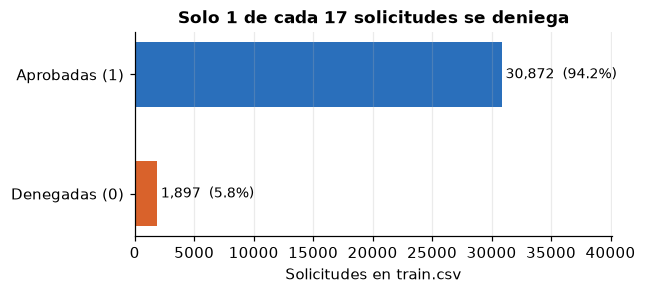

In [3]:
vc = train[S.TARGET].value_counts().sort_index()
rate_deny = vc[0] / len(train)
print(f"Aprobadas (1): {vc[1]:,} ({1-rate_deny:.2%})   Denegadas (0): {vc[0]:,} ({rate_deny:.2%})")

fig, ax = plt.subplots(figsize=(5.6, 2.4))
ax.barh(["Denegadas (0)", "Aprobadas (1)"], [vc[0], vc[1]], color=[ORANGE, BLUE], height=0.55)
for yy, v in enumerate([vc[0], vc[1]]):
    ax.text(v + 300, yy, f"{v:,}  ({v/len(train):.1%})", va="center", fontsize=9)
ax.set_xlim(0, vc.max() * 1.3); ax.set_xlabel("Solicitudes en train.csv"); ax.grid(axis="y", visible=False)
ax.set_title("Solo 1 de cada 17 solicitudes se deniega")
plt.show()

**Lectura.** Si el modelo aprobara *todo*, acertaría ~94 % y aun así sería inútil —y peligroso—: **la exactitud (accuracy) no sirve como métrica**. Lo que importa es *qué errores* comete y *qué tan seguros son los casos que decide solo*.

## 3. Matriz de impacto: Acceso Indebido vs. Demora de Productividad

En lugar de poner un precio en dólares (que el dataset no trae y habría que inventar), se describe el **impacto cualitativo** de cada resultado de la decisión en cinco dimensiones. Las puntuaciones (1 = bajo … 5 = crítico) son **juicio experto de trabajo, a validar con Seguridad, Riesgos y Cumplimiento**; sirven para razonar la asimetría, no son datos medidos.

In [4]:
impact = pd.DataFrame(
    {
        "Seguridad (superficie de ataque, mov. lateral)": [5, 1, 1, 2],
        "Cumplimiento / auditoría": [5, 1, 1, 2],
        "Productividad del usuario": [1, 4, 1, 3],
        "Reversibilidad (qué tan fácil es corregir)": [2, 5, 5, 4],   # 5 = fácil de corregir
        "Detectabilidad (¿se nota rápido?)": [1, 5, 5, 4],          # 5 = se detecta rápido
    },
    index=["Acceso indebido concedido (FP)", "Acceso legítimo demorado/bloqueado (FN)", "Aprobación legítima automática (VP)", "Revisión humana (cola del analista)"],
)
display(impact.style.background_gradient(cmap="Reds", axis=None, subset=impact.columns[:3]).format("{:.0f}"))
print("Escala 1-5. En 'Reversibilidad' y 'Detectabilidad' un valor ALTO es BUENO (fácil de corregir / se nota rápido).")

,"Seguridad (superficie de ataque, mov. lateral)",Cumplimiento / auditoría,Productividad del usuario,Reversibilidad (qué tan fácil es corregir),Detectabilidad (¿se nota rápido?)
Acceso indebido concedido (FP),5,5,1,2,1
Acceso legítimo demorado/bloqueado (FN),1,1,4,5,5
Aprobación legítima automática (VP),1,1,1,5,5
Revisión humana (cola del analista),2,2,3,4,4


Escala 1-5. En 'Reversibilidad' y 'Detectabilidad' un valor ALTO es BUENO (fácil de corregir / se nota rápido).


**Qué dice la matriz.**

* El **acceso indebido (FP)** es el único resultado crítico en seguridad **y** cumplimiento, y es el **menos detectable**: un privilegio de más no da síntomas hasta que alguien lo abusa o lo encuentra la auditoría. Es difícil de revertir a tiempo.
* El **acceso legítimo demorado (FN)** daña la productividad, pero es **muy visible** (el usuario abre un ticket) y **fácil de corregir** en minutos u horas.
* La **revisión humana** es barata en riesgo pero tiene un costo oculto: la **fatiga de aprobación**. Una cola demasiado larga o poco informativa degrada la calidad del analista, y justo ahí se cuelan los accesos indebidos.
* Conclusión de diseño (sin necesidad de un precio): ante la duda, **escalar a un humano**; auto-aprobar solo cuando el riesgo observable sea mínimo; no auto-denegar sin posibilidad de apelación.

## 4. Métricas de éxito (marco Zero Trust / IGA)

| # | Métrica | Definición | Meta |
|---|---|---|---|
| 1 | **Tasa de Auto-Aprobación Segura** (*Auto-Approval Rate*, AAR) | % del total de solicitudes que el modelo aprueba **sin humano** y **sin conceder ningún acceso indebido** (FPR = 0 %). Variante práctica: aprobadas con confianza `p ≥ 0,98` | Maximizar con **0 falsos positivos** |
| 2 | **Reducción de fricción y SLA** | Latencia de decisión de los accesos legítimos (de días con aprobación manual a **milisegundos** en la auto-aprobación) | Medir latencia del modelo; medir el SLA manual actual con tickets reales |
| 3 | **Triaje asistido (human-in-the-loop)** | Lo ambiguo o anómalo se canaliza a analistas IAM. Se mide la **carga de revisión** y el ***lift*** de la cola (tasa de denegaciones en la cola ÷ tasa global) para **prevenir la fatiga de aprobación** | Cola corta y enriquecida en casos riesgosos |
| — | Métricas técnicas de apoyo | ROC-AUC; PR-AUC de la clase *denegar*; precisión en zonas de ultra-alta confianza | Comparar modelos |

**Cuidado con "FPR = 0 %".** Observar 0 falsos positivos en una muestra no prueba que la tasa real sea 0. Con *n* negativos, la cota superior al 95 % es ≈ 3 / *n* (regla de tres). Aquí hay unos 1.900 negativos en `train.csv`: aun con 0 errores observados, la tasa real podría ser de ≈ 0,16 %. Por eso toda cifra de AAR @ FPR = 0 se acompaña de esa cota.

In [5]:
n_neg = int((train[S.TARGET] == 0).sum())
print(f"Negativos (debían denegarse) en train: {n_neg:,} → con 0 FP observados, FPR real ≤ {fpr_upper_bound(0, n_neg):.3%} (95 %)")
print(f"Meta de FPR del proyecto: {S.TARGET_FPR:.0%} · confianza de auto-aprobación práctica: p ≥ {S.AUTO_APPROVE_CONFIDENCE}")

Negativos (debían denegarse) en train: 1,897 → con 0 FP observados, FPR real ≤ 0.158% (95 %)
Meta de FPR del proyecto: 0% · confianza de auto-aprobación práctica: p ≥ 0.98


## 5. Líneas base (lo que hay que superar)

Todas se evalúan **fuera de pliegue**, con 5 pliegues `StratifiedGroupKFold` por gerente **solo sobre el entrenamiento** (la reserva cerrada y `test.csv` no se tocan). Ninguna usa un modelo de ML salvo la regla de historial del recurso.

1. **Aprobar todo:** 100 % automático, pero concede todos los accesos indebidos. Viola Zero Trust.
2. **Denegar todo:** 0 accesos indebidos, pero bloquea al 100 % de los legítimos. Inviable.
3. **Revisión manual del 100 %:** 0 accesos indebidos (revisor perfecto) con **carga humana del 100 %** y 0 % de auto-aprobación: es la referencia de seguridad, y el origen de la fricción y la fatiga.
4. **Regla del historial del recurso:** auto-aprobar si la tasa de aprobación (suavizada) del recurso en el entrenamiento es ≥ 0,98; el resto va a revisión humana (los recursos nunca vistos también).

In [6]:
a, g_rate = 5, None
y = train[S.TARGET].to_numpy()
p_rule = np.zeros(len(train))
for tr, va in make_cv(5, S.SEED).split(train, y, groups=train[S.GROUP_COL]):
    fit = train.iloc[tr]
    g_rate = fit[S.TARGET].mean()
    st = fit.groupby("RESOURCE")[S.TARGET].agg(["sum", "count"])
    smoothed = (st["sum"] + a * g_rate) / (st["count"] + a)                 # tasa suavizada: a solicitudes "virtuales" a la tasa global
    p_rule[va] = train.iloc[va]["RESOURCE"].map(smoothed).fillna(0.0).to_numpy()   # recurso nunca visto -> 0 -> revisión humana

rows = []
n = len(train)
def row(name, auto_mask, note):
    fp = int((auto_mask & (y == 0)).sum()); auto = int(auto_mask.sum())
    rows.append({"Política": name, "% auto-aprobado": auto / n, "Accesos indebidos concedidos (FP)": fp,
                 "FPR": fp / n_neg, "% a revisión humana": 1 - auto / n if name != "2. Denegar todo" else 0.0,
                 "% legítimos bloqueados": (1.0 if name == "2. Denegar todo" else 0.0), "Nota": note})
row("1. Aprobar todo", np.ones(n, bool), "viola Zero Trust")
row("2. Denegar todo", np.zeros(n, bool), "inviable")
row("3. Revisión manual 100 %", np.zeros(n, bool), "seguro pero con fricción y fatiga máximas")
row("4. Regla historial del recurso (p ≥ 0,98)", p_rule >= S.AUTO_APPROVE_CONFIDENCE, "el resto a revisión")
z = auto_approval_at_zero_fpr(y, p_rule)
row("4b. Misma regla con umbral FPR = 0 %", p_rule > z["threshold"], f"umbral {z['threshold']:.3f}")
base = pd.DataFrame(rows).set_index("Política")
base.style.format({"% auto-aprobado": "{:.2%}", "FPR": "{:.2%}", "% a revisión humana": "{:.1%}", "% legítimos bloqueados": "{:.0%}"})

,% auto-aprobado,Accesos indebidos concedidos (FP),FPR,% a revisión humana,% legítimos bloqueados,Nota
Política,,,,,,
1. Aprobar todo,100.00%,1897,100.00%,0.0%,0%,viola Zero Trust
2. Denegar todo,0.00%,0,0.00%,0.0%,100%,inviable
3. Revisión manual 100 %,0.00%,0,0.00%,100.0%,0%,seguro pero con fricción y fatiga máximas
"4. Regla historial del recurso (p ≥ 0,98)",18.10%,161,8.49%,81.9%,0%,el resto a revisión
4b. Misma regla con umbral FPR = 0 %,0.00%,0,0.00%,100.0%,0%,umbral 0.998


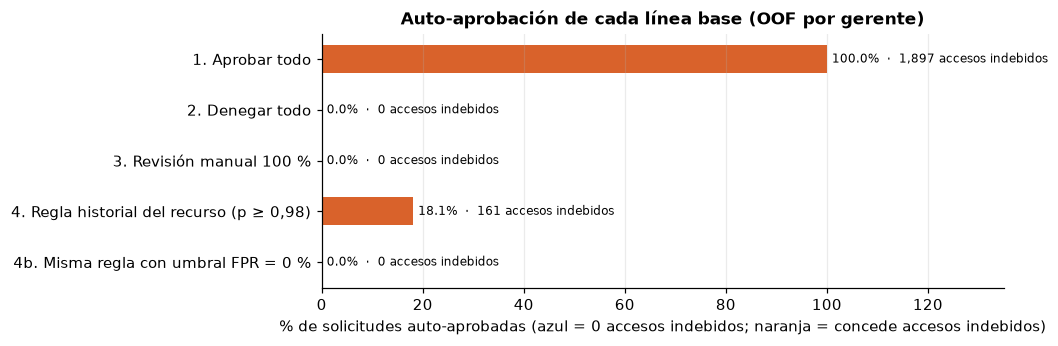

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.0))
ax.barh(base.index[::-1], base["% auto-aprobado"].values[::-1] * 100, color=[BLUE if fp == 0 else ORANGE for fp in base["Accesos indebidos concedidos (FP)"].values[::-1]], height=0.55)
for yy, (v, fp) in enumerate(zip(base["% auto-aprobado"].values[::-1], base["Accesos indebidos concedidos (FP)"].values[::-1])):
    ax.text(v * 100 + 1, yy, f"{v:.1%}  ·  {fp:,} accesos indebidos", va="center", fontsize=8)
ax.set_xlim(0, 135); ax.grid(axis="y", visible=False); ax.set_xlabel("% de solicitudes auto-aprobadas (azul = 0 accesos indebidos; naranja = concede accesos indebidos)")
ax.set_title("Auto-aprobación de cada línea base (OOF por gerente)")
plt.show()

**Lectura de las líneas base.**

* Las únicas políticas con **0 accesos indebidos** son *denegar todo* (inviable), *revisión manual 100 %* y la regla con umbral estricto: lo seguro es, hoy, **revisar casi todo**. Esa es la fricción que el proyecto quiere reducir.
* La regla del historial del recurso a `p ≥ 0,98` auto-aprueba ≈ 18 % de las solicitudes, pero **concede 161 accesos indebidos** (FPR ≈ 8,5 %): rendimiento aparente sin seguridad. Con el umbral estricto de FPR = 0 % (4b) **no auto-aprueba nada (0 %)**: la historia del recurso sola no basta para una zona segura.
* **El listón del modelo:** auto-aprobar una fracción **mayor que la regla estricta (4b, 0 %)** **sin** conceder accesos indebidos, y entregar al analista una cola **más informativa**. Cualquier ganancia debe compararse con ese número, no con "aprobar todo".

## 6. Riesgos, límites y supuestos

- **Sin costos ni SLA reales:** el dataset no trae costos, tiempos de espera ni criticidad de recursos. La reducción de SLA "de días a milisegundos" se **medirá en milisegundos para el modelo**, pero el lado manual **debe medirse con tickets reales** (no se asume aquí).
- **Etiqueta = decisión humana histórica.** `ACTION` dice qué *decidió un revisor*, no qué era *correcto*. Si los revisores se equivocaron o fueron sesgados, el modelo lo aprende. Antes de automatizar hay que auditar una muestra.
- **Fuga por partición:** un mismo gerente y un mismo recurso aparecen muchas veces. Partir por fila infla el desempeño (se demuestra en `03_preprocesamiento`). La partición es **por `MGR_ID`**.
- **Variables anónimas:** todo son códigos; no se puede interpretar el *significado* de un rol ni conocer la criticidad del recurso. La explicabilidad será por patrón.
- **Zero Trust y adversarios:** un atacante podría intentar que sus solicitudes parezcan "rutinarias". La auto-aprobación debe tener controles adicionales (alertas de anomalía, re-certificación periódica de accesos).
- **Equidad / uso responsable:** el modelo no debe usarse para sancionar a personas; las denegaciones deben poder apelarse, y toda decisión automática se registra para auditoría.
- **Deriva:** en `test.csv` hay gerentes y familias de rol que no existen en `train.csv`; lo desconocido se **escala a humano**.
- **`test.csv` no tiene etiqueta**: no sirve para medir desempeño; solo para generar predicciones.

## 7. Decisiones del caso (copiar a `reports/00_caso.md` y a la sección 7 de `especificacion-proyecto.md`)

| # | Decisión | Motivo |
|---|---|---|
| 1 | Clase positiva = **aprobar** (`ACTION=1`); FP = **acceso indebido concedido**, FN = acceso legítimo demorado | Alinea el lenguaje del modelo con el riesgo de seguridad |
| 2 | **Reorientación:** el éxito se mide con **Auto-Aprobación Segura (FPR = 0 %)**, reducción de fricción/SLA y triaje asistido; se abandona el costo en USD | El dataset no trae costos; los montos eran supuestos arbitrarios. Zero Trust prioriza no conceder accesos indebidos |
| 3 | Ante la duda, **escalar a un analista IAM**; no auto-denegar | Menor Privilegio y Zero Trust; evitar bloqueos sin apelación |
| 4 | Toda cifra de FPR = 0 % se acompaña de su cota superior al 95 % | 0 errores observados no prueban 0 errores reales |
| 5 | Partición por **gerente** (`MGR_ID`), reserva cerrada | Un gerente decide de forma correlacionada: partir por fila filtraría información |
| 6 | Línea base a superar: **regla del historial del recurso con umbral estricto** y la revisión manual 100 % | Un modelo debe justificar su complejidad frente a reglas simples |
| 7 | El SLA manual actual y la criticidad de los recursos son **datos por obtener** | No están en el dataset; no se inventan |